# EDA

In [327]:
import pandas as pd
import numpy as np

In [328]:
event_details = pd.read_csv("data/ufc_event_details.csv")
fight_results = pd.read_csv("data/ufc_fight_results.csv")
fight_stats = pd.read_csv("data/ufc_fight_stats.csv")
fighter_tott = pd.read_csv("data/ufc_fighter_tott.csv")

ed_df = pd.DataFrame(event_details)
fr_df = pd.DataFrame(fight_results)
fs_df = pd.DataFrame(fight_stats)
ft_df = pd.DataFrame(fighter_tott)

### Cleanning ufc_event_details

In [329]:
ed_df.head()

,EVENT,URL,DATE,LOCATION
0,UFC Fight Night: Moicano vs. Nolan,http://ufcstats.com/event-details/0a66de3a797c...,"October 31, 2026","Las Vegas, Nevada, USA"
1,UFC 333: Volkanovski vs. Evloev,http://ufcstats.com/event-details/cc18abc046b3...,"October 24, 2026","Abu Dhabi, Abu Dhabi, United Arab Emirates"
2,UFC Fight Night: Buckley vs. Malott,http://ufcstats.com/event-details/55e94a9b525d...,"October 17, 2026","Edmonton, Alberta, Canada"
3,UFC Fight Night: Allen vs. Duncan,http://ufcstats.com/event-details/7f98d9d5a10f...,"October 10, 2026","Las Vegas, Nevada, USA"
4,UFC 332: Silva vs. Wang,http://ufcstats.com/event-details/ad3fdba28a75...,"October 03, 2026","Salt Lake City, Utah, USA"


In [330]:
ed_df = ed_df.drop(["URL", "LOCATION"], axis=1)
ed_df.head()

,EVENT,DATE
0,UFC Fight Night: Moicano vs. Nolan,"October 31, 2026"
1,UFC 333: Volkanovski vs. Evloev,"October 24, 2026"
2,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
3,UFC Fight Night: Allen vs. Duncan,"October 10, 2026"
4,UFC 332: Silva vs. Wang,"October 03, 2026"


### Cleanning ufc_fight_results

In [331]:
fr_df.head()

,EVENT,BOUT,OUTCOME,WEIGHTCLASS,METHOD,ROUND,TIME,TIME FORMAT,REFEREE,DETAILS,URL
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,L/W,Lightweight Bout,KO/TKO,3,1:28,5 Rnd (5-5-5-5-5),Dan Miragliotta,Elbows to Head From Half Guard,http://ufcstats.com/fight-details/6d7244be5589...
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,L/W,Welterweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),Herb Dean,Mike Bell 26 - 30.Eric Colon 26 - 30.Junichiro...,http://ufcstats.com/fight-details/d37d3af2529c...
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,L/W,Flyweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),Kerry Hatley,Derek Cleary 28 - 29.Sal D'amato 28 - 29.Bryan...,http://ufcstats.com/fight-details/b74a628c5fa4...
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,L/W,Women's Bantamweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),Chris Tognoni,Derek Cleary 28 - 29.Eric Colon 28 - 29.Sal D'...,http://ufcstats.com/fight-details/d08ad0f685b8...
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,W/L,Welterweight Bout,TKO - Doctor's Stoppage,3,2:11,3 Rnd (5-5-5),Dan Miragliotta,Facial cut,http://ufcstats.com/fight-details/a7b3c1386172...


In [332]:
fr_df["TIME FORMAT"].value_counts()

TIME FORMAT
3 Rnd (5-5-5)           7937
5 Rnd (5-5-5-5-5)        802
1 Rnd + OT (12-3)         88
3 Rnd + OT (5-5-5-5)      46
No Time Limit             31
1 Rnd (20)                25
1 Rnd + 2OT (15-3-3)      20
2 Rnd (5-5)               14
1 Rnd (15)                12
1 Rnd (10)                 7
1 Rnd (12)                 6
1 Rnd + OT (30-5)          3
1 Rnd + OT (15-3)          2
1 Rnd (18)                 2
3 Rnd (10-5-5)             1
1 Rnd + 2OT (24-3-3)       1
1 Rnd + OT (27-3)          1
1 Rnd + OT (30-3)          1
1 Rnd (30)                 1
1 Rnd + OT (31-5)          1
Name: count, dtype: int64

In [333]:
fr_df = fr_df.drop(["URL", "DETAILS", "REFEREE"], axis=1)

In [334]:
fr_df = fr_df[fr_df["TIME FORMAT"].isin(["5 Rnd (5-5-5-5-5)", "3 Rnd (5-5-5)"])]
fr_df["TIME FORMAT"].head()

0    5 Rnd (5-5-5-5-5)
1        3 Rnd (5-5-5)
2        3 Rnd (5-5-5)
3        3 Rnd (5-5-5)
4        3 Rnd (5-5-5)
Name: TIME FORMAT, dtype: str

In [335]:
len(fr_df)

8739

In [336]:
fr_df["scheduled_rounds"] = fr_df["TIME FORMAT"].str[0].astype(int)
fr_df.head()

,EVENT,BOUT,OUTCOME,WEIGHTCLASS,METHOD,ROUND,TIME,TIME FORMAT,scheduled_rounds
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,L/W,Lightweight Bout,KO/TKO,3,1:28,5 Rnd (5-5-5-5-5),5
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,L/W,Welterweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,L/W,Flyweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,L/W,Women's Bantamweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,W/L,Welterweight Bout,TKO - Doctor's Stoppage,3,2:11,3 Rnd (5-5-5),3


In [337]:
fr_df["total_time"] = (fr_df["ROUND"].astype(int) - 1) * 5 * 60 + (fr_df["TIME"].str[0].astype(int) * 60 + fr_df["TIME"].str[2:].astype(int))
fr_df.head()

,EVENT,BOUT,OUTCOME,WEIGHTCLASS,METHOD,ROUND,TIME,TIME FORMAT,scheduled_rounds,total_time
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,L/W,Lightweight Bout,KO/TKO,3,1:28,5 Rnd (5-5-5-5-5),5,688
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,L/W,Welterweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3,900
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,L/W,Flyweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3,900
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,L/W,Women's Bantamweight Bout,Decision - Unanimous,3,5:00,3 Rnd (5-5-5),3,900
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,W/L,Welterweight Bout,TKO - Doctor's Stoppage,3,2:11,3 Rnd (5-5-5),3,731


In [338]:
fr_df = fr_df.drop(["TIME", "TIME FORMAT", "ROUND"], axis=1)
fr_df.head()

,EVENT,BOUT,OUTCOME,WEIGHTCLASS,METHOD,scheduled_rounds,total_time
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,L/W,Lightweight Bout,KO/TKO,5,688
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,L/W,Welterweight Bout,Decision - Unanimous,3,900
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,L/W,Flyweight Bout,Decision - Unanimous,3,900
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,L/W,Women's Bantamweight Bout,Decision - Unanimous,3,900
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,W/L,Welterweight Bout,TKO - Doctor's Stoppage,3,731


In [339]:
fr_df["OUTCOME"].value_counts()

OUTCOME
W/L      5421
L/W      3166
NC/NC      90
D/D        62
Name: count, dtype: int64

In [340]:
parts = fr_df["BOUT"].str.strip().str.split(" vs. ", expand=True)
parts.shape 

(8739, 2)

In [341]:
fr_df["fighter_a"] = parts[0].str.strip()
fr_df["fighter_b"] = parts[1].str.strip()

In [342]:
fr_df[["BOUT", "fighter_a", "fighter_b", "OUTCOME"]].head()
fr_df[["fighter_a", "fighter_b"]].isna().sum()

fighter_a    0
fighter_b    0
dtype: int64

In [343]:
fr_df["a_wins"] = fr_df["OUTCOME"].str.strip().map({"W/L": 1, "L/W": 0})
fr_df["a_wins"].value_counts(dropna=False)

a_wins
1.0    5421
0.0    3166
NaN     152
Name: count, dtype: int64

In [344]:
fr_df["WEIGHTCLASS"].value_counts()

WEIGHTCLASS
Lightweight Bout                                              1418
Welterweight Bout                                             1355
Middleweight Bout                                             1114
Featherweight Bout                                             863
Bantamweight Bout                                              774
                                                              ... 
Ultimate Fighter 2 Welterweight Tournament Title Bout            1
Ultimate Fighter 1 Light Heavyweight Tournament Title Bout       1
Ultimate Fighter 1 Middleweight Tournament Title Bout            1
Super Heavyweight Bout                                           1
Ultimate Japan 2 Heavyweight Tournament Title Bout               1
Name: count, Length: 71, dtype: int64

In [345]:
wc = fr_df["WEIGHTCLASS"].str.strip()

# 1. Banderas (ANTES de normalizar)
fr_df["is_women"] = wc.str.contains("Women").astype(int)
fr_df["is_title"] = wc.str.contains("Title").astype(int)

# 2. Función: devuelve la primera categoría que encuentre en el texto
CLASSES = [
    "Light Heavyweight", "Super Heavyweight", "Heavyweight",   # orden importante
    "Middleweight", "Welterweight", "Lightweight", "Featherweight",
    "Bantamweight", "Flyweight", "Strawweight", "Catch Weight",
]

def normalize_weight_class(text):
    for c in CLASSES:
        if c in text:
            return c
    return "Other"

# 3. Aplicarla a cada fila
fr_df["weight_class"] = wc.map(normalize_weight_class)
fr_df["weight_class"].value_counts()

weight_class
Lightweight          1465
Welterweight         1415
Middleweight         1164
Bantamweight         1063
Featherweight         921
Light Heavyweight     774
Heavyweight           745
Flyweight             720
Strawweight           385
Catch Weight           84
Other                   2
Super Heavyweight       1
Name: count, dtype: int64

In [346]:
fr_df = fr_df[~fr_df["weight_class"].isin(["Super Heavyweight", "Other"])]
fr_df = fr_df.drop(columns=["WEIGHTCLASS"])

In [347]:
fr_df = fr_df.drop(["OUTCOME"], axis=1)
fr_df.head()

,EVENT,BOUT,METHOD,scheduled_rounds,total_time,fighter_a,fighter_b,a_wins,is_women,is_title,weight_class
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,KO/TKO,5,688,Renato Moicano,Tom Nolan,0.0,0,0,Lightweight
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,Decision - Unanimous,3,900,Randy Brown,Jacobe Smith,0.0,0,0,Welterweight
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,Decision - Unanimous,3,900,Ode Osbourne,Cody Durden,0.0,0,0,Flyweight
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,Decision - Unanimous,3,900,Yana Santos,Luana Santos,0.0,1,0,Bantamweight
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,TKO - Doctor's Stoppage,3,731,Jean-Paul Lebosnoyani,Farman Hasanov,1.0,0,0,Welterweight


### Cleanning ufc_fight_stats

In [348]:
fs_df.head()

,EVENT,BOUT,ROUND,FIGHTER,KD,SIG.STR.,SIG.STR. %,TOTAL STR.,TD,TD %,SUB.ATT,REV.,CTRL,HEAD,BODY,LEG,DISTANCE,CLINCH,GROUND
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Renato Moicano,0.0,2 of 2,100%,13 of 18,1 of 1,100%,1.0,0.0,4:07,0 of 0,2 of 2,0 of 0,2 of 2,0 of 0,0 of 0
1,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Renato Moicano,0.0,4 of 7,57%,31 of 39,1 of 3,33%,0.0,0.0,3:02,2 of 4,1 of 2,1 of 1,4 of 7,0 of 0,0 of 0
2,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 3,Renato Moicano,0.0,3 of 3,100%,3 of 3,1 of 1,100%,0.0,0.0,0:08,1 of 1,2 of 2,0 of 0,3 of 3,0 of 0,0 of 0
3,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Tom Nolan,0.0,4 of 8,50%,26 of 34,0 of 0,---,0.0,0.0,0:00,2 of 6,1 of 1,1 of 1,4 of 8,0 of 0,0 of 0
4,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Tom Nolan,1.0,25 of 35,71%,101 of 112,1 of 1,100%,0.0,0.0,0:33,18 of 27,6 of 7,1 of 1,15 of 25,2 of 2,8 of 8


In [349]:
parts_sig = fs_df["SIG.STR."].str.strip().str.split(" of ", expand=True)
parts_tot = fs_df["TOTAL STR."].str.strip().str.split(" of ", expand=True)
print(parts_sig.shape)
print(parts_tot.shape )

(42288, 2)
(42288, 2)


In [350]:
fs_df["sig_str_landed"] = parts_sig[0].str.strip()
fs_df["sig_str_throw"] = parts_sig[1].str.strip()
fs_df["tot_str_landed"] = parts_tot[0].str.strip()
fs_df["tot_str_throw"] = parts_tot[1].str.strip()

fs_df.head()

,EVENT,BOUT,ROUND,FIGHTER,KD,SIG.STR.,SIG.STR. %,TOTAL STR.,TD,TD %,...,HEAD,BODY,LEG,DISTANCE,CLINCH,GROUND,sig_str_landed,sig_str_throw,tot_str_landed,tot_str_throw
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Renato Moicano,0.0,2 of 2,100%,13 of 18,1 of 1,100%,...,0 of 0,2 of 2,0 of 0,2 of 2,0 of 0,0 of 0,2,2,13,18
1,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Renato Moicano,0.0,4 of 7,57%,31 of 39,1 of 3,33%,...,2 of 4,1 of 2,1 of 1,4 of 7,0 of 0,0 of 0,4,7,31,39
2,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 3,Renato Moicano,0.0,3 of 3,100%,3 of 3,1 of 1,100%,...,1 of 1,2 of 2,0 of 0,3 of 3,0 of 0,0 of 0,3,3,3,3
3,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Tom Nolan,0.0,4 of 8,50%,26 of 34,0 of 0,---,...,2 of 6,1 of 1,1 of 1,4 of 8,0 of 0,0 of 0,4,8,26,34
4,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Tom Nolan,1.0,25 of 35,71%,101 of 112,1 of 1,100%,...,18 of 27,6 of 7,1 of 1,15 of 25,2 of 2,8 of 8,25,35,101,112


In [351]:
fs_df = fs_df.dropna(subset=["FIGHTER"])

OF_COLS = {
    "SIG.STR.": "sig_str", "TOTAL STR.": "total_str", "TD": "td",
    "HEAD": "head", "BODY": "body", "LEG": "leg",
    "DISTANCE": "distance", "CLINCH": "clinch", "GROUND": "ground",
}

for col, name in OF_COLS.items():
    parts = fs_df[col].str.strip().str.split(" of ", expand=True)
    fs_df[f"{name}_landed"] = parts[0].str.strip().astype(int)
    fs_df[f"{name}_attempted"] = parts[1].str.strip().astype(int)

In [352]:
for col, name in OF_COLS.items():

    fs_df = fs_df.drop([col], axis=1)

fs_df = fs_df.drop(["SIG.STR. %", "TD %"], axis=1)

fs_df.head()

,EVENT,BOUT,ROUND,FIGHTER,KD,SUB.ATT,REV.,CTRL,sig_str_landed,sig_str_throw,...,body_landed,body_attempted,leg_landed,leg_attempted,distance_landed,distance_attempted,clinch_landed,clinch_attempted,ground_landed,ground_attempted
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Renato Moicano,0.0,1.0,0.0,4:07,2,2,...,2,2,0,0,2,2,0,0,0,0
1,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Renato Moicano,0.0,0.0,0.0,3:02,4,7,...,1,2,1,1,4,7,0,0,0,0
2,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 3,Renato Moicano,0.0,0.0,0.0,0:08,3,3,...,2,2,0,0,3,3,0,0,0,0
3,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 1,Tom Nolan,0.0,0.0,0.0,0:00,4,8,...,1,1,1,1,4,8,0,0,0,0
4,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Round 2,Tom Nolan,1.0,0.0,0.0,0:33,25,35,...,6,7,1,1,15,25,2,2,8,8


In [353]:
ctrl = fs_df["CTRL"].str.strip().replace("--", np.nan)
t = ctrl.str.split(":", expand=True)
fs_df["ctrl_seconds"] = t[0].astype(float) * 60 + t[1].astype(float)

fs_df = fs_df.rename(columns={"KD": "kd", "SUB.ATT": "sub_att", "REV.": "rev"})
fs_df = fs_df.drop(columns=["CTRL", "ROUND"])

In [354]:
fs_df.head()

,EVENT,BOUT,FIGHTER,kd,sub_att,rev,sig_str_landed,sig_str_throw,tot_str_landed,tot_str_throw,...,body_attempted,leg_landed,leg_attempted,distance_landed,distance_attempted,clinch_landed,clinch_attempted,ground_landed,ground_attempted,ctrl_seconds
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Renato Moicano,0.0,1.0,0.0,2,2,13,18,...,2,0,0,2,2,0,0,0,0,247.0
1,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Renato Moicano,0.0,0.0,0.0,4,7,31,39,...,2,1,1,4,7,0,0,0,0,182.0
2,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Renato Moicano,0.0,0.0,0.0,3,3,3,3,...,2,0,0,3,3,0,0,0,0,8.0
3,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Tom Nolan,0.0,0.0,0.0,4,8,26,34,...,1,1,1,4,8,0,0,0,0,0.0
4,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,Tom Nolan,1.0,0.0,0.0,25,35,101,112,...,7,1,1,15,25,2,2,8,8,33.0


In [355]:
fs_df.dtypes

EVENT                      str
BOUT                       str
FIGHTER                    str
kd                     float64
sub_att                float64
rev                    float64
sig_str_landed           int64
sig_str_throw              str
tot_str_landed             str
tot_str_throw              str
sig_str_attempted        int64
total_str_landed         int64
total_str_attempted      int64
td_landed                int64
td_attempted             int64
head_landed              int64
head_attempted           int64
body_landed              int64
body_attempted           int64
leg_landed               int64
leg_attempted            int64
distance_landed          int64
distance_attempted       int64
clinch_landed            int64
clinch_attempted         int64
ground_landed            int64
ground_attempted         int64
ctrl_seconds           float64
dtype: object

In [356]:
fs_df["sig_str_throw"] = fs_df["sig_str_throw"].astype("int64")
fs_df["tot_str_landed"] = fs_df["tot_str_landed"].astype("int64")
fs_df["tot_str_throw"] = fs_df["tot_str_throw"].astype("int64")

fs_df.dtypes

EVENT                      str
BOUT                       str
FIGHTER                    str
kd                     float64
sub_att                float64
rev                    float64
sig_str_landed           int64
sig_str_throw            int64
tot_str_landed           int64
tot_str_throw            int64
sig_str_attempted        int64
total_str_landed         int64
total_str_attempted      int64
td_landed                int64
td_attempted             int64
head_landed              int64
head_attempted           int64
body_landed              int64
body_attempted           int64
leg_landed               int64
leg_attempted            int64
distance_landed          int64
distance_attempted       int64
clinch_landed            int64
clinch_attempted         int64
ground_landed            int64
ground_attempted         int64
ctrl_seconds           float64
dtype: object

In [357]:
fs_fight = (
    fs_df
    .groupby(["EVENT", "BOUT", "FIGHTER"], as_index=False)
    .sum(min_count=1)
)
fs_fight.head()

,EVENT,BOUT,FIGHTER,kd,sub_att,rev,sig_str_landed,sig_str_throw,tot_str_landed,tot_str_throw,...,body_attempted,leg_landed,leg_attempted,distance_landed,distance_attempted,clinch_landed,clinch_attempted,ground_landed,ground_attempted,ctrl_seconds
0,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Alex Reyes,0.0,0.0,0.0,14,38,15,39,...,4,4,4,12,32,2,6,0,0,1.0
1,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Charlie Campbell,1.0,0.0,0.0,43,72,43,72,...,13,6,6,35,60,7,10,1,2,2.0
2,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Alexa Grasso,1.0,1.0,1.0,84,203,262,408,...,22,18,30,51,160,31,35,2,8,159.0
3,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Valentina Shevchenko,0.0,1.0,0.0,80,179,199,301,...,8,13,13,67,158,6,8,7,13,517.0
4,Noche UFC: Grasso vs. Shevchenko 2,Daniel Zellhuber vs. Christos Giagos,Christos Giagos,0.0,0.0,0.0,38,82,38,82,...,7,10,12,36,79,2,3,0,0,11.0


In [358]:
print(fs_fight.shape )                                
print(fs_fight.groupby(["EVENT", "BOUT"]).size().value_counts() )

(17958, 28)
2    8979
Name: count, dtype: int64


In [359]:
b = "Renato Moicano vs. Tom Nolan"
fs_df[fs_df["BOUT"] == b].groupby("FIGHTER")["sig_str_landed"].sum()
fs_fight[fs_fight["BOUT"] == b][["FIGHTER", "sig_str_landed"]]

,FIGHTER,sig_str_landed
13626,Renato Moicano,9
13627,Tom Nolan,69


In [360]:
fs_fight.columns

Index(['EVENT', 'BOUT', 'FIGHTER', 'kd', 'sub_att', 'rev', 'sig_str_landed',
       'sig_str_throw', 'tot_str_landed', 'tot_str_throw', 'sig_str_attempted',
       'total_str_landed', 'total_str_attempted', 'td_landed', 'td_attempted',
       'head_landed', 'head_attempted', 'body_landed', 'body_attempted',
       'leg_landed', 'leg_attempted', 'distance_landed', 'distance_attempted',
       'clinch_landed', 'clinch_attempted', 'ground_landed',
       'ground_attempted', 'ctrl_seconds'],
      dtype='str')

In [361]:
KEEP = ["EVENT", "BOUT", "FIGHTER",
        "sig_str_landed", "sig_str_attempted",
        "total_str_landed", "total_str_attempted",
        "td_landed", "td_attempted", "ctrl_seconds",
        "kd", "sub_att"]
fs_fight = fs_fight[KEEP]

fs_fight.head()

,EVENT,BOUT,FIGHTER,sig_str_landed,sig_str_attempted,total_str_landed,total_str_attempted,td_landed,td_attempted,ctrl_seconds,kd,sub_att
0,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Alex Reyes,14,38,15,39,0,2,1.0,0.0,0.0
1,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Charlie Campbell,43,72,43,72,0,0,2.0,1.0,0.0
2,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Alexa Grasso,84,203,262,408,1,2,159.0,1.0,1.0
3,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Valentina Shevchenko,80,179,199,301,4,7,517.0,0.0,1.0
4,Noche UFC: Grasso vs. Shevchenko 2,Daniel Zellhuber vs. Christos Giagos,Christos Giagos,38,82,38,82,0,6,11.0,0.0,0.0


In [362]:
opp = fs_fight.rename(columns={"FIGHTER": "OPPONENT"})
fs_full = fs_fight.merge(opp, on=["EVENT", "BOUT"], suffixes=("", "_opp"))
fs_full = fs_full[fs_full["FIGHTER"] != fs_full["OPPONENT"]]
print(fs_full.shape)
print(fs_fight.shape)

(17958, 22)
(17958, 12)


In [363]:
fs_full.head()

,EVENT,BOUT,FIGHTER,sig_str_landed,sig_str_attempted,total_str_landed,total_str_attempted,td_landed,td_attempted,ctrl_seconds,...,OPPONENT,sig_str_landed_opp,sig_str_attempted_opp,total_str_landed_opp,total_str_attempted_opp,td_landed_opp,td_attempted_opp,ctrl_seconds_opp,kd_opp,sub_att_opp
1,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Alex Reyes,14,38,15,39,0,2,1.0,...,Charlie Campbell,43,72,43,72,0,0,2.0,1.0,0.0
2,Noche UFC: Grasso vs. Shevchenko 2,Alex Reyes vs. Charlie Campbell,Charlie Campbell,43,72,43,72,0,0,2.0,...,Alex Reyes,14,38,15,39,0,2,1.0,0.0,0.0
5,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Alexa Grasso,84,203,262,408,1,2,159.0,...,Valentina Shevchenko,80,179,199,301,4,7,517.0,0.0,1.0
6,Noche UFC: Grasso vs. Shevchenko 2,Alexa Grasso vs. Valentina Shevchenko,Valentina Shevchenko,80,179,199,301,4,7,517.0,...,Alexa Grasso,84,203,262,408,1,2,159.0,1.0,1.0
9,Noche UFC: Grasso vs. Shevchenko 2,Daniel Zellhuber vs. Christos Giagos,Christos Giagos,38,82,38,82,0,6,11.0,...,Daniel Zellhuber,36,101,36,101,0,0,17.0,0.0,1.0


In [364]:
fr_df.head()

,EVENT,BOUT,METHOD,scheduled_rounds,total_time,fighter_a,fighter_b,a_wins,is_women,is_title,weight_class
0,UFC Fight Night: Moicano vs. Nolan,Renato Moicano vs. Tom Nolan,KO/TKO,5,688,Renato Moicano,Tom Nolan,0.0,0,0,Lightweight
1,UFC Fight Night: Moicano vs. Nolan,Randy Brown vs. Jacobe Smith,Decision - Unanimous,3,900,Randy Brown,Jacobe Smith,0.0,0,0,Welterweight
2,UFC Fight Night: Moicano vs. Nolan,Ode Osbourne vs. Cody Durden,Decision - Unanimous,3,900,Ode Osbourne,Cody Durden,0.0,0,0,Flyweight
3,UFC Fight Night: Moicano vs. Nolan,Yana Santos vs. Luana Santos,Decision - Unanimous,3,900,Yana Santos,Luana Santos,0.0,1,0,Bantamweight
4,UFC Fight Night: Moicano vs. Nolan,Jean-Paul Lebosnoyani vs. Farman Hasanov,TKO - Doctor's Stoppage,3,731,Jean-Paul Lebosnoyani,Farman Hasanov,1.0,0,0,Welterweight


In [365]:
for df in (fs_full, fr_df):
    df["EVENT"] = df["EVENT"].str.strip()
    df["BOUT"] = df["BOUT"].str.strip()

ed_df["EVENT"] = ed_df["EVENT"].str.strip()

In [366]:
df = fs_full.merge(fr_df, on=["EVENT", "BOUT"], how="inner")
df.shape

(17472, 31)

In [367]:
df["win"] = np.where(
    df["FIGHTER"] == df["fighter_a"],  
    df["a_wins"],                       
    1 - df["a_wins"],                   
)

In [368]:
mask = (df["FIGHTER"] != df["fighter_a"]) & (df["FIGHTER"] != df["fighter_b"])
mask.sum()

np.int64(0)

In [369]:
df = df.merge(ed_df[["EVENT", "DATE"]], on="EVENT", how="left")
df["DATE"] = pd.to_datetime(df["DATE"])
df = df.sort_values(["DATE", "EVENT", "BOUT"]).reset_index(drop=True)
df = df.drop(columns=["fighter_a", "fighter_b", "a_wins"])

df["DATE"].isna().sum()
df.head()

,EVENT,BOUT,FIGHTER,sig_str_landed,sig_str_attempted,total_str_landed,total_str_attempted,td_landed,td_attempted,ctrl_seconds,...,kd_opp,sub_att_opp,METHOD,scheduled_rounds,total_time,is_women,is_title,weight_class,win,DATE
0,UFC 21: Return of the Champions,Eugene Jackson vs. Royce Alger,Eugene Jackson,21,46,27,52,0,0,20.0,...,0.0,0.0,KO/TKO,3,379,0,0,Middleweight,1.0,1999-07-16
1,UFC 21: Return of the Champions,Eugene Jackson vs. Royce Alger,Royce Alger,11,26,12,27,2,8,153.0,...,1.0,1.0,KO/TKO,3,379,0,0,Middleweight,0.0,1999-07-16
2,UFC 21: Return of the Champions,Jeremy Horn vs. Daiju Takase,Daiju Takase,0,14,1,15,0,1,0.0,...,0.0,0.0,KO/TKO,3,281,0,0,Middleweight,0.0,1999-07-16
3,UFC 21: Return of the Champions,Jeremy Horn vs. Daiju Takase,Jeremy Horn,35,59,51,76,0,0,178.0,...,0.0,0.0,KO/TKO,3,281,0,0,Middleweight,1.0,1999-07-16
4,UFC 21: Return of the Champions,Maurice Smith vs. Marco Ruas,Marco Ruas,1,1,4,6,1,1,221.0,...,0.0,0.0,KO/TKO,3,300,0,0,Heavyweight,0.0,1999-07-16


In [370]:
df.columns

Index(['EVENT', 'BOUT', 'FIGHTER', 'sig_str_landed', 'sig_str_attempted',
       'total_str_landed', 'total_str_attempted', 'td_landed', 'td_attempted',
       'ctrl_seconds', 'kd', 'sub_att', 'OPPONENT', 'sig_str_landed_opp',
       'sig_str_attempted_opp', 'total_str_landed_opp',
       'total_str_attempted_opp', 'td_landed_opp', 'td_attempted_opp',
       'ctrl_seconds_opp', 'kd_opp', 'sub_att_opp', 'METHOD',
       'scheduled_rounds', 'total_time', 'is_women', 'is_title',
       'weight_class', 'win', 'DATE'],
      dtype='str')

## Cleanning fighter tott

In [371]:
ft_df.head()

,FIGHTER,HEIGHT,WEIGHT,REACH,STANCE,DOB,URL
0,Tom Aaron,--,155 lbs.,--,NaN,"Jul 13, 1978",http://ufcstats.com/fighter-details/93fe7332d1...
1,Danny Abbadi,"5' 11""",155 lbs.,--,Orthodox,"Jul 03, 1983",http://ufcstats.com/fighter-details/15df64c02b...
2,Nariman Abbasov,"5' 8""",155 lbs.,"66""",Orthodox,"Feb 01, 1994",http://ufcstats.com/fighter-details/59a9d6dac6...
3,Darion Abbey,"6' 2""",265 lbs.,"80""",Orthodox,"Feb 25, 1993",http://ufcstats.com/fighter-details/4961467134...
4,David Abbott,"6' 0""",265 lbs.,--,Switch,"Apr 26, 1965",http://ufcstats.com/fighter-details/b361180739...


In [372]:
ft_df.dtypes

FIGHTER    str
HEIGHT     str
WEIGHT     str
REACH      str
STANCE     str
DOB        str
URL        str
dtype: object

In [373]:
reach = ft_df["REACH"].str.strip().str.replace('"', "", regex=False)
ft_df["reach_cm"] = pd.to_numeric(reach, errors="coerce") * 2.54

ft_df["reach_cm"].describe()       
ft_df["reach_cm"].isna().sum() 

np.int64(2139)

In [374]:
ft_df.head()

,FIGHTER,HEIGHT,WEIGHT,REACH,STANCE,DOB,URL,reach_cm
0,Tom Aaron,--,155 lbs.,--,NaN,"Jul 13, 1978",http://ufcstats.com/fighter-details/93fe7332d1...,NaN
1,Danny Abbadi,"5' 11""",155 lbs.,--,Orthodox,"Jul 03, 1983",http://ufcstats.com/fighter-details/15df64c02b...,NaN
2,Nariman Abbasov,"5' 8""",155 lbs.,"66""",Orthodox,"Feb 01, 1994",http://ufcstats.com/fighter-details/59a9d6dac6...,167.64
3,Darion Abbey,"6' 2""",265 lbs.,"80""",Orthodox,"Feb 25, 1993",http://ufcstats.com/fighter-details/4961467134...,203.20
4,David Abbott,"6' 0""",265 lbs.,--,Switch,"Apr 26, 1965",http://ufcstats.com/fighter-details/b361180739...,NaN


In [375]:
ft_df = ft_df.drop(columns=["WEIGHT", "URL"])

In [376]:
ft_df["HEIGHT"] = ft_df["HEIGHT"].str.strip().replace("--", np.nan)

parts = ft_df["HEIGHT"].str.strip().str.replace('"', "", regex=False).str.split("'", expand=True)

feet = pd.to_numeric(parts[0].str.strip(), errors="coerce")
inch = pd.to_numeric(parts[1].str.strip(), errors="coerce")
ft_df["height_cm"] = (feet * 12 + inch) * 2.54

ft_df["height_cm"].isna().sum() 
ft_df["height_cm"].describe()       

count    4112.000000
mean      178.153327
std         8.972295
min       139.700000
25%       172.720000
50%       177.800000
75%       185.420000
max       226.060000
Name: height_cm, dtype: float64

In [377]:
ft_df.head()

,FIGHTER,HEIGHT,REACH,STANCE,DOB,reach_cm,height_cm
0,Tom Aaron,NaN,--,NaN,"Jul 13, 1978",NaN,NaN
1,Danny Abbadi,"5' 11""",--,Orthodox,"Jul 03, 1983",NaN,180.34
2,Nariman Abbasov,"5' 8""","66""",Orthodox,"Feb 01, 1994",167.64,172.72
3,Darion Abbey,"6' 2""","80""",Orthodox,"Feb 25, 1993",203.20,187.96
4,David Abbott,"6' 0""",--,Switch,"Apr 26, 1965",NaN,182.88


In [378]:
ft_df = ft_df.drop(columns=["HEIGHT", "REACH"])

In [379]:
ft_df["DOB"] = pd.to_datetime(ft_df["DOB"].str.strip(), format="%b %d, %Y", errors="coerce")

print(ft_df["DOB"].isna().sum())
ft_df["DOB"].agg(["min", "max"])

779


min   1943-01-25
max   2005-12-20
Name: DOB, dtype: datetime64[us]

In [380]:
ft_df.head()

,FIGHTER,STANCE,DOB,reach_cm,height_cm
0,Tom Aaron,NaN,1978-07-13,NaN,NaN
1,Danny Abbadi,Orthodox,1983-07-03,NaN,180.34
2,Nariman Abbasov,Orthodox,1994-02-01,167.64,172.72
3,Darion Abbey,Orthodox,1993-02-25,203.20,187.96
4,David Abbott,Switch,1965-04-26,NaN,182.88


In [381]:
ft_df["STANCE"] = ft_df["STANCE"].fillna("Unknown")
ft_df.head()

,FIGHTER,STANCE,DOB,reach_cm,height_cm
0,Tom Aaron,Unknown,1978-07-13,NaN,NaN
1,Danny Abbadi,Orthodox,1983-07-03,NaN,180.34
2,Nariman Abbasov,Orthodox,1994-02-01,167.64,172.72
3,Darion Abbey,Orthodox,1993-02-25,203.20,187.96
4,David Abbott,Switch,1965-04-26,NaN,182.88


In [382]:
ft_df["STANCE"].value_counts()

STANCE
Orthodox       2768
Unknown        1023
Southpaw        609
Switch          219
Open Stance       7
Sideways          3
Name: count, dtype: int64

In [383]:
ft_df["STANCE"] = ft_df["STANCE"].replace({"Open Stance": "Unknown", "Sideways": "Unknown"})

In [384]:
dup_names = ft_df.loc[ft_df["FIGHTER"].duplicated(keep=False), "FIGHTER"].unique()

ft_df = ft_df[~ft_df["FIGHTER"].isin(dup_names)]
df = df[~df["FIGHTER"].isin(dup_names) & ~df["OPPONENT"].isin(dup_names)]

In [385]:
n_before = len(df)
df = df.merge(
    ft_df[["FIGHTER", "height_cm", "reach_cm", "STANCE", "DOB"]],
    on="FIGHTER", how="left",
)
assert len(df) == n_before

In [386]:
df["age"] = (df["DATE"] - df["DOB"]).dt.days / 365.25
df = df.drop(columns=["DOB"])
df["age"].describe()

count    17191.000000
mean        30.523663
std          4.146294
min         18.171116
25%         27.567420
50%         30.349076
75%         33.267625
max         47.854894
Name: age, dtype: float64

In [387]:
df.columns

Index(['EVENT', 'BOUT', 'FIGHTER', 'sig_str_landed', 'sig_str_attempted',
       'total_str_landed', 'total_str_attempted', 'td_landed', 'td_attempted',
       'ctrl_seconds', 'kd', 'sub_att', 'OPPONENT', 'sig_str_landed_opp',
       'sig_str_attempted_opp', 'total_str_landed_opp',
       'total_str_attempted_opp', 'td_landed_opp', 'td_attempted_opp',
       'ctrl_seconds_opp', 'kd_opp', 'sub_att_opp', 'METHOD',
       'scheduled_rounds', 'total_time', 'is_women', 'is_title',
       'weight_class', 'win', 'DATE', 'height_cm', 'reach_cm', 'STANCE',
       'age'],
      dtype='str')

In [388]:
df = df.sort_values(["DATE", "EVENT", "BOUT"]).reset_index(drop=True)
g = df.groupby("FIGHTER")

In [389]:
df["prev_fights"] = g.cumcount()

In [390]:
w = df["win"].fillna(0)
df["prev_wins"] = w.groupby(df["FIGHTER"]).cumsum() - w

In [391]:
df.loc[df["FIGHTER"] == "Renato Moicano",
       ["DATE", "OPPONENT", "win", "prev_fights", "prev_wins"]]

,DATE,OPPONENT,win,prev_fights,prev_wins
5626,2014-12-20,Tom Niinimaki,1.0,0,0.0
6872,2016-05-14,Zubaira Tukhugov,1.0,1,1.0
7759,2017-04-15,Jeremy Stephens,1.0,2,2.0
8037,2017-07-29,Brian Ortega,0.0,3,3.0
8667,2018-04-07,Calvin Kattar,1.0,4,3.0
8995,2018-08-04,Cub Swanson,1.0,5,4.0
9425,2019-02-02,Jose Aldo,0.0,6,5.0
9853,2019-06-22,Chan Sung Jung,0.0,7,5.0
10599,2020-03-14,Damir Hadzovic,1.0,8,5.0
11293,2020-12-12,Rafael Fiziev,0.0,9,6.0


In [392]:
STATS = [
    "sig_str_landed", "sig_str_attempted",
    "total_str_landed", "total_str_attempted",
    "td_landed", "td_attempted", "ctrl_seconds", "kd", "sub_att",
    "sig_str_landed_opp", "sig_str_attempted_opp",
    "td_landed_opp", "td_attempted_opp", "ctrl_seconds_opp", "kd_opp",
    "total_time",
]

for col in STATS:
    x = df[col].fillna(0)
    df[f"prev_{col}"] = x.groupby(df["FIGHTER"]).cumsum() - x

In [393]:
ctrl_known_time = df["total_time"].where(df["ctrl_seconds"].notna(), 0)
df["prev_ctrl_time"] = ctrl_known_time.groupby(df["FIGHTER"]).cumsum() - ctrl_known_time

In [394]:
mins = df["prev_total_time"] / 60
df["slpm"]        = df["prev_sig_str_landed"] / mins                
df["sapm"]        = df["prev_sig_str_landed_opp"] / mins             
df["str_acc"]     = df["prev_sig_str_landed"] / df["prev_sig_str_attempted"]
df["str_def"]     = 1 - df["prev_sig_str_landed_opp"] / df["prev_sig_str_attempted_opp"]
df["ctrl_pct"]    = df["prev_ctrl_seconds"] / df["prev_ctrl_time"]
df["win_rate"]    = df["prev_wins"] / df["prev_fights"]

In [395]:
df.loc[df["FIGHTER"] == "Renato Moicano",
       ["DATE", "prev_fights", "win_rate", "slpm", "sapm", "str_acc", "str_def", "ctrl_pct"]].tail()

,DATE,prev_fights,win_rate,slpm,sapm,str_acc,str_def,ctrl_pct
15119,2024-09-28,16,0.687500,4.379078,3.675771,0.481400,0.606813,0.210328
15395,2025-01-18,17,0.705882,4.417712,3.602613,0.492030,0.605854,0.227626
15861,2025-06-28,18,0.666667,4.362864,3.549757,0.489116,0.606855,0.221986
16625,2026-04-04,19,0.631579,4.171301,3.565072,0.489876,0.598119,0.210882
17306,2026-10-31,20,0.650000,4.100337,3.552562,0.492023,0.596862,0.219021


In [396]:
# --- 1. Ratios de lucha y finalización ---
df["td_avg"]  = df["prev_td_landed"] / mins * 15
df["td_acc"]  = df["prev_td_landed"] / df["prev_td_attempted"]
df["td_def"]  = 1 - df["prev_td_landed_opp"] / df["prev_td_attempted_opp"]
df["sub_avg"] = df["prev_sub_att"] / mins * 15
df["kd_avg"]  = df["prev_kd"] / mins * 15
df = df.replace([np.inf, -np.inf], np.nan)

# --- 2. Listas de features ---
FIGHTER_FEATS = [
    "prev_fights", "prev_wins", "win_rate",
    "slpm", "sapm", "str_acc", "str_def",
    "td_avg", "td_acc", "td_def", "sub_avg", "kd_avg", "ctrl_pct",
    "height_cm", "reach_cm", "age",
]
CONTEXT = ["weight_class", "is_title", "is_women", "scheduled_rounds"]

# --- 3. Lado A y lado B (rival) ---
side_a = df[["EVENT", "BOUT", "DATE", "FIGHTER", "OPPONENT", "STANCE", "win"]
            + CONTEXT + FIGHTER_FEATS]

side_b = df[["EVENT", "BOUT", "FIGHTER", "STANCE"] + FIGHTER_FEATS].rename(
    columns={"FIGHTER": "OPPONENT", "STANCE": "STANCE_b",
             **{c: f"{c}_b" for c in FIGHTER_FEATS}}
)

fights = side_a.merge(side_b, on=["EVENT", "BOUT", "OPPONENT"], how="inner")
assert len(fights) == len(df)

# --- 4. Diferencias A − B y guardia ---
for c in FIGHTER_FEATS:
    fights[f"{c}_diff"] = fights[c] - fights[f"{c}_b"]
fights["same_stance"] = (fights["STANCE"] == fights["STANCE_b"]).astype(int)

# --- 5. Dataset final ---
DIFF_FEATS = [f"{c}_diff" for c in FIGHTER_FEATS]
FEATURES = DIFF_FEATS + CONTEXT + ["STANCE", "STANCE_b", "same_stance",
                                   "prev_fights", "prev_fights_b"]

model_df = fights.dropna(subset=["win"]).copy()
model_df = model_df[["DATE", "EVENT", "BOUT", "FIGHTER", "OPPONENT"] + FEATURES + ["win"]]
model_df["win"] = model_df["win"].astype(int)

print(model_df.shape)
print(model_df["win"].mean())   # ≈ 0.50
model_df[model_df["BOUT"] == "Renato Moicano vs. Tom Nolan"].T

(17064, 31)
0.5


,17306,17307
DATE,2026-10-31 00:00:00,2026-10-31 00:00:00
EVENT,UFC Fight Night: Moicano vs. Nolan,UFC Fight Night: Moicano vs. Nolan
BOUT,Renato Moicano vs. Tom Nolan,Renato Moicano vs. Tom Nolan
FIGHTER,Renato Moicano,Tom Nolan
OPPONENT,Tom Nolan,Renato Moicano
prev_fights_diff,14,-14
prev_wins_diff,8.0,-8.0
win_rate_diff,-0.183333,0.183333
slpm_diff,-0.620428,0.620428
sapm_diff,-0.242563,0.242563


In [397]:
model_df["DATE"].isna().sum()                          # 44
model_df.loc[model_df["DATE"].isna(), "EVENT"].unique()

<StringArray>
[                   'UFC - Road to UFC 4.6',
 'UFC Fight Night: Grasso vs. Shevchenko 2',
         'UFC Fight Night: Lopes vs. Silva']
Length: 3, dtype: str

# EDA

In [398]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss, mutual_info_score
import xgboost as xgb

from features import build_datasets, FIGHTER_FEATS, CONTEXT

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [399]:
model_df, snapshot = build_datasets()
model_df["DATE"].isna().sum()      # debe dar 0

np.int64(0)

In [400]:
train = model_df[model_df["DATE"] < "2023-01-01"]
val = model_df[(model_df["DATE"] >= "2023-01-01") & (model_df["DATE"] < "2025-01-01")]
test = model_df[model_df["DATE"] >= "2025-01-01"]

In [401]:
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, d.shape, d["DATE"].min().date(), d["DATE"].max().date(), round(d["win"].mean(), 3))

assert len(train) + len(val) + len(test) == len(model_df)

train (13104, 31) 1999-07-16 2022-12-17 0.5
val (1986, 31) 2023-01-14 2024-12-14 0.5
test (1934, 31) 2025-01-11 2026-10-31 0.5


### Target variable

The target `win` is perfectly balanced (6,552 wins vs 6,552 losses in the training set). This is by design, not a property of the raw data: every fight appears **twice** in the dataset, once from each fighter's perspective (fighter vs opponent, and opponent vs fighter), with mirrored features and opposite labels.

This symmetric setup removes a strong ordering bias in the source data. In the original UFC Stats listings, the first fighter in the `BOUT` column wins ~63% of the time, so a model trained on that order would learn "the first fighter usually wins" instead of comparing the two fighters. With both perspectives included, the model can only rely on the differences between the fighters.

Because the classes are balanced, **ROC AUC** (and accuracy as a secondary metric) is an appropriate evaluation metric. **Log loss** is also tracked, since the service returns win probabilities.

Draws and no contests were excluded from the target (they are still counted in each fighter's fight history).

In [402]:
model_df["win"].mean()

np.float64(0.5)

In [403]:
train["win"].value_counts()

win
1    6552
0    6552
Name: count, dtype: int64

### Missing values

Most missing values are **structural**, not data errors:

- **~26% (win_rate, slpm, sapm, td_avg, kd_avg, sub_avg, ctrl_pct, str_acc, str_def):** at least one of the two fighters is making his UFC debut, so he has no fight history and the difference A − B cannot be computed. This share is higher in the training period, which includes the early UFC years.
- **td_acc (~39%) and td_def (~36%):** in addition to debutants, these ratios are undefined (0/0) when a fighter has never attempted a takedown, or never had one attempted against him.
- **reach_cm (~12%):** reach is not recorded on UFC Stats for many fighters, mostly those with few UFC fights.
- **age, height_cm, STANCE (<1%):** fighters with no date of birth or physical profile on UFC Stats.

Dropping these rows would remove about a third of the data and would make the model unable to predict fights involving debutants. Instead:
- XGBoost handles missing values natively.
- For logistic regression and random forest, missing values are imputed with the **median of the training set** (fitted on train only).
- `prev_fights` and `prev_fights_b` are kept as features so the model knows when the statistics come from little or no history.

In [404]:
train.isna().mean().sort_values(ascending=False)

td_acc_diff         0.389499
td_def_diff         0.364011
slpm_diff           0.333944
sapm_diff           0.333944
td_avg_diff         0.333944
kd_avg_diff         0.333944
sub_avg_diff        0.333944
str_acc_diff        0.262515
str_def_diff        0.261752
win_rate_diff       0.260836
ctrl_pct_diff       0.260836
reach_cm_diff       0.124847
age_diff            0.009310
height_cm_diff      0.000763
prev_wins_diff      0.000000
FIGHTER             0.000000
DATE                0.000000
EVENT               0.000000
BOUT                0.000000
prev_fights_diff    0.000000
OPPONENT            0.000000
weight_class        0.000000
is_title            0.000000
is_women            0.000000
scheduled_rounds    0.000000
STANCE              0.000000
STANCE_b            0.000000
same_stance         0.000000
prev_fights         0.000000
prev_fights_b       0.000000
win                 0.000000
dtype: float64

### Value ranges

- All `_diff` features are centred at 0 with symmetric min/max values. This is expected, because every fight appears from both perspectives (A − B and B − A).
- Physical differences are realistic: height and reach differences of up to ±33 cm, and age differences of up to ±18 years.
- Ratio features (`str_acc`, `str_def`, `td_acc`, `td_def`, `ctrl_pct`, `win_rate`) stay within [−1, 1], as expected for differences of proportions.
- `scheduled_rounds` only takes values 3 and 5, and about 5% of the bouts are title fights and 9.5% are women's fights.

**Outliers in per-minute rates.** `slpm_diff`, `td_avg_diff`, `sub_avg_diff` and especially `kd_avg_diff` (up to ±128) show extreme values. They are not data errors: they come from fighters with very little previous cage time. For example, a single prior fight that ended in a 7-second knockout gives 1 knockdown in 7 seconds ≈ 128 knockdowns per 15 minutes. These estimates are unreliable and can distort linear models.

To handle this, per-minute rates are set to missing when a fighter has **less than 5 minutes** of previous UFC fight time, and are then treated like the rest of the missing history (imputed or handled natively by XGBoost). The same rule is applied when building the fighter snapshot used by the prediction service.

In [405]:
train.describe().T

,count,mean,min,25%,50%,75%,max,std
DATE,13104,2015-06-20 13:06:35.604395,1999-07-16 00:00:00,2012-02-25 00:00:00,2016-02-06 00:00:00,2019-08-03 00:00:00,2022-12-17 00:00:00,NaN
prev_fights_diff,13104.0,0.0,-38.0,-3.0,0.0,3.0,38.0,6.231951
prev_wins_diff,13104.0,0.0,-22.0,-2.0,0.0,2.0,22.0,3.918443
win_rate_diff,9686.0,0.0,-1.0,-0.169231,0.0,0.169231,1.0,0.319845
slpm_diff,8728.0,0.0,-18.142208,-1.115767,0.0,1.115767,18.142208,1.903463
sapm_diff,8728.0,0.0,-12.9353,-0.946312,0.0,0.946312,12.9353,1.742732
str_acc_diff,9664.0,0.0,-0.805556,-0.084398,0.0,0.084398,0.805556,0.144384
str_def_diff,9674.0,0.0,-0.740741,-0.079851,0.0,0.079851,0.740741,0.140626
td_avg_diff,8728.0,0.0,-10.876133,-1.181455,0.0,1.181455,10.876133,2.094189
td_acc_diff,8000.0,0.0,-1.0,-0.207054,0.0,0.207054,1.0,0.340811


### Distributions of key features

All four differences are symmetric and centred at 0, as expected from the mirrored dataset.

- **age_diff** is roughly normal, mostly within ±10 years.
- **reach_cm_diff** shows gaps between bars because reach is recorded in whole inches, so differences are multiples of 2.54 cm.
- **win_rate_diff** has spikes at 0, ±0.5 and ±1. These come from fighters with very few previous fights (e.g. 1/1 or 1/2 records) and from bouts between two unbeaten fighters (1 − 1 = 0).
- **slpm_diff** is concentrated within about ±5 strikes per minute.

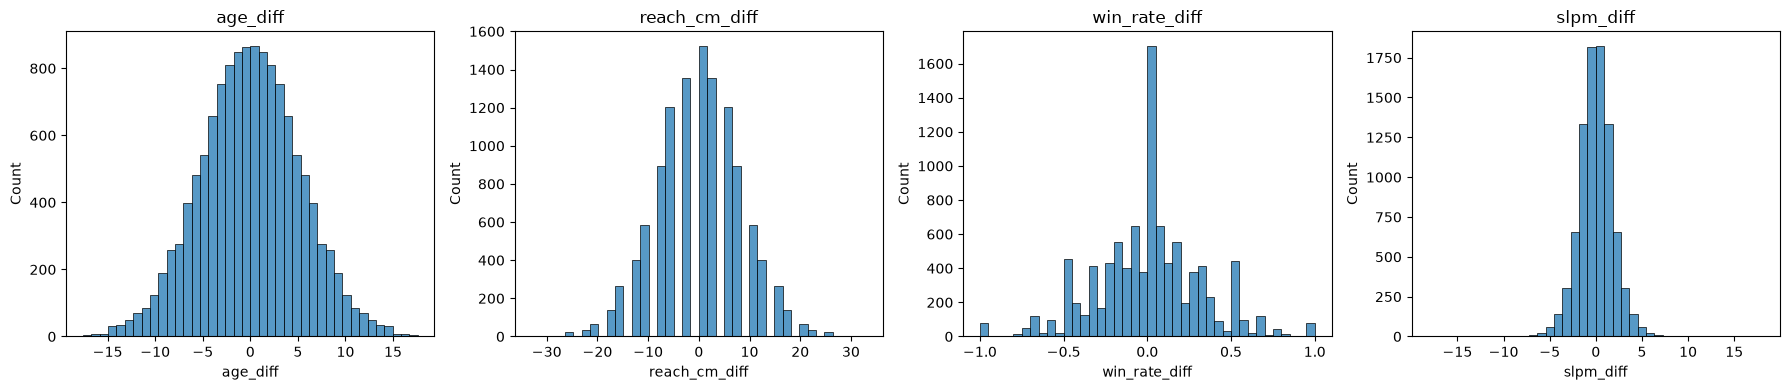

In [406]:
KEY = ["age_diff", "reach_cm_diff", "win_rate_diff", "slpm_diff"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, KEY):
    sns.histplot(train[col].dropna(), bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()

### Win rate by feature (deciles)

Each feature was split into 10 equal-sized bins and the share of wins was computed per bin (red line = 50%).

- **age_diff:** the clearest signal. The younger fighter wins about **61%** of the time in the most extreme bin, and the older fighter only about **39%**. Age is a key factor in a sport with fast physical decline.
- **win_rate_diff:** the fighter with the better previous record wins more often, from ~42% up to ~59%.
- **reach_cm_diff:** a smaller but consistent effect: a longer reach increases the win rate from ~44% to ~56%.
- **slpm_diff:** fighters who land more significant strikes per minute win slightly more often (~45% → ~55%).

All relationships go in the expected direction, but individually they are **moderate**. MMA outcomes are hard to predict (even betting markets are wrong in roughly one out of three fights), so a realistic goal is a model that combines these weak signals into a ROC AUC clearly above 0.5, rather than near-perfect accuracy.

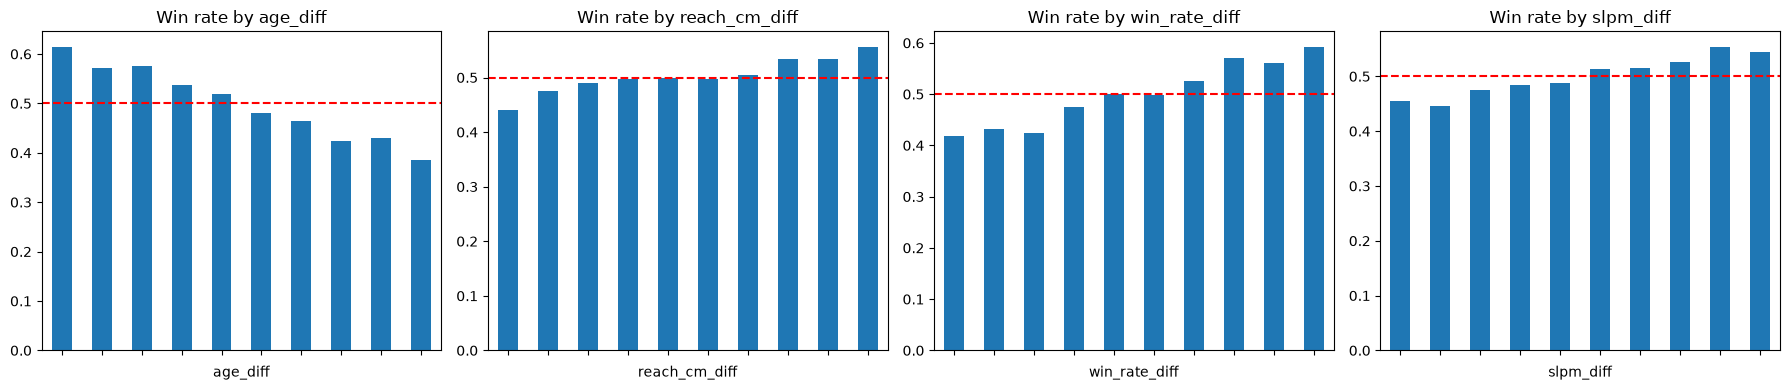

In [407]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, KEY):
    bins = pd.qcut(train[col], 10, duplicates="drop")
    train.groupby(bins, observed=True)["win"].mean().plot(kind="bar", ax=ax)
    ax.axhline(0.5, color="red", linestyle="--")
    ax.set_title(f"Win rate by {col}")
    ax.set_xticklabels([])
plt.tight_layout()

### Feature importance (numerical): single-feature ROC AUC

Each numerical feature was evaluated on its own with ROC AUC on the training set (rows with missing values for that feature were excluded). An AUC below 0.5 means an **inverse** relationship, so the strength of a feature is its distance from 0.5.

- **Strongest:** `age_diff` (AUC 0.42 → 0.58 inverted; the younger fighter wins more), `sapm_diff` (0.43 → 0.57 inverted; absorbing more strikes per minute is bad), `win_rate_diff` (0.57) and `str_def_diff` (0.57).
- **Moderate (0.53–0.56):** takedown volume and defense, control time, previous wins, striking volume and accuracy, reach.
- **Weak (< 0.52):** `kd_avg_diff`, `sub_avg_diff` and the raw number of previous fights.

No single feature exceeds 0.58, which confirms that each one is only a weak signal on its own. They are all kept for modelling: tree-based models can combine them and use `prev_fights` to judge how reliable the other statistics are. Weak features will be dropped later if removing them does not reduce validation AUC.

In [408]:
num_feats = [c for c in train.columns if c.endswith("_diff")] + ["prev_fights", "prev_fights_b"]

aucs = {}
for col in num_feats:
    d = train[[col, "win"]].dropna()
    aucs[col] = roc_auc_score(d["win"], d[col])

pd.Series(aucs).sort_values(ascending=False)

win_rate_diff       0.568775
str_def_diff        0.566643
td_avg_diff         0.558402
ctrl_pct_diff       0.547001
td_def_diff         0.544995
prev_wins_diff      0.544247
slpm_diff           0.539127
str_acc_diff        0.535904
reach_cm_diff       0.535124
td_acc_diff         0.528917
height_cm_diff      0.524539
prev_fights_diff    0.523055
prev_fights         0.518410
sub_avg_diff        0.513781
kd_avg_diff         0.509691
prev_fights_b       0.481590
sapm_diff           0.428111
age_diff            0.415886
dtype: float64

In [409]:
s = pd.Series(aucs)
(s - 0.5).abs().sort_values(ascending=False)

age_diff            0.084114
sapm_diff           0.071889
win_rate_diff       0.068775
str_def_diff        0.066643
td_avg_diff         0.058402
ctrl_pct_diff       0.047001
td_def_diff         0.044995
prev_wins_diff      0.044247
slpm_diff           0.039127
str_acc_diff        0.035904
reach_cm_diff       0.035124
td_acc_diff         0.028917
height_cm_diff      0.024539
prev_fights_diff    0.023055
prev_fights         0.018410
prev_fights_b       0.018410
sub_avg_diff        0.013781
kd_avg_diff         0.009691
dtype: float64

### Feature importance (categorical)

**Context features** (`weight_class`, `is_title`, `is_women`, `scheduled_rounds`, `same_stance`) have a win rate of exactly 0.5 in every category and a mutual information of 0. This is expected: both rows of a fight share these values, one labelled as a win and one as a loss, so on their own they cannot predict the winner. They are kept because tree-based models can use them as **interactions** (e.g. the effect of cardio-related stats may differ in 5-round fights or across weight classes). Linear models cannot exploit them.

**Stance** has a small effect (mutual information ≈ 0.0008):
- Southpaws beat orthodox fighters **54%** of the time, consistent with the well-known southpaw advantage: most opponents are used to facing orthodox fighters.
- Fighters with **unknown stance** win only **~26%** of their fights (62 rows). The stance itself is not the cause: an incomplete profile on UFC Stats usually belongs to fighters with a short UFC career. This is an example of **informative missingness**.

In [410]:
CAT_FEATS = ["weight_class", "is_title", "is_women", "scheduled_rounds",
             "same_stance", "STANCE", "STANCE_b"]

# 2. % de victorias y nº de filas por valor
for col in CAT_FEATS:
    print(f"\n--- {col} ---")
    print(train.groupby(col)["win"].agg(["mean", "count"]).round(3))

# 3. Mutual information con el target
mi = {col: mutual_info_score(train[col].fillna("Unknown").astype(str), train["win"])
      for col in CAT_FEATS}
pd.Series(mi).sort_values(ascending=False)


--- weight_class ---
                   mean  count
weight_class                  
Bantamweight        0.5   1452
Catch Weight        0.5    106
Featherweight       0.5   1316
Flyweight           0.5    890
Heavyweight         0.5   1178
Light Heavyweight   0.5   1228
Lightweight         0.5   2320
Middleweight        0.5   1784
Strawweight         0.5    496
Welterweight        0.5   2334

--- is_title ---
          mean  count
is_title             
0          0.5  12420
1          0.5    684

--- is_women ---
          mean  count
is_women             
0          0.5  11858
1          0.5   1246

--- scheduled_rounds ---
                  mean  count
scheduled_rounds             
3                  0.5  11930
5                  0.5   1174

--- same_stance ---
             mean  count
same_stance             
0             0.5   5012
1             0.5   8092

--- STANCE ---
           mean  count
STANCE                
Orthodox  0.494   9851
Southpaw  0.526   2607
Switch    0.515    

STANCE_b            8.421515e-04
STANCE              8.421515e-04
is_title            1.665335e-15
same_stance         1.110223e-15
weight_class        0.000000e+00
is_women            0.000000e+00
scheduled_rounds    0.000000e+00
dtype: float64

STANCE_b,Orthodox,Southpaw,Switch,Unknown
STANCE,,,,
Orthodox,7486.0,1911.0,407.0,47.0
Southpaw,1911.0,556.0,124.0,16.0
Switch,407.0,124.0,50.0,1.0
Unknown,47.0,16.0,1.0,NaN


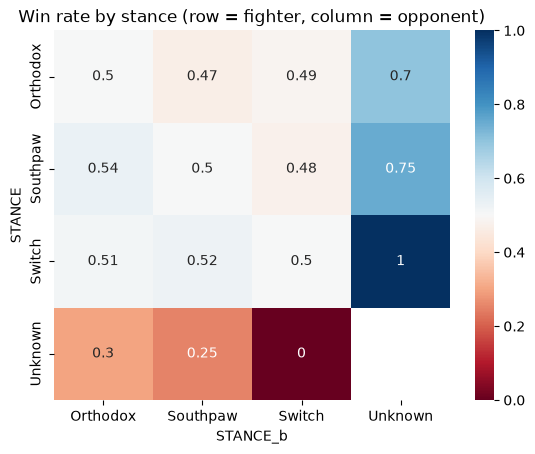

In [411]:
# 4. Cruce de guardias: % de victorias del FIGHTER según su guardia y la del rival
stance_matrix = train.pivot_table(index="STANCE", columns="STANCE_b",
                                  values="win", aggfunc="mean").round(3)
stance_counts = train.pivot_table(index="STANCE", columns="STANCE_b",
                                  values="win", aggfunc="count")

sns.heatmap(stance_matrix, annot=True, cmap="RdBu", center=0.5)
plt.title("Win rate by stance (row = fighter, column = opponent)")
stance_counts

### Correlation between features

Most feature differences are only weakly correlated, so each one adds some independent information. The notable pairs are:

- **`prev_fights_diff` vs `prev_wins_diff` (0.95):** almost redundant, because fighters with more fights also tend to have more wins. `prev_wins_diff` is **dropped**: experience is already captured by `prev_fights_diff`, and record quality by `win_rate_diff` (correlation of only 0.11 with it).
- **`td_avg_diff` vs `ctrl_pct_diff` (0.71):** wrestlers who land more takedowns spend more time in control. Both are kept, as they measure volume and dominance respectively.
- **`height_cm_diff` vs `reach_cm_diff` (0.63):** taller fighters usually have a longer reach, but not always, so both are kept.
- **`age_diff` vs `prev_fights_diff` (0.35):** older fighters tend to be more experienced.
- **`ctrl_pct_diff` vs `sapm_diff` (−0.38):** fighters who control their opponents absorb fewer strikes.

Moderate correlations are not a problem for tree-based models. For logistic regression, regularization (tuned through `C`) will help to stabilise the coefficients.

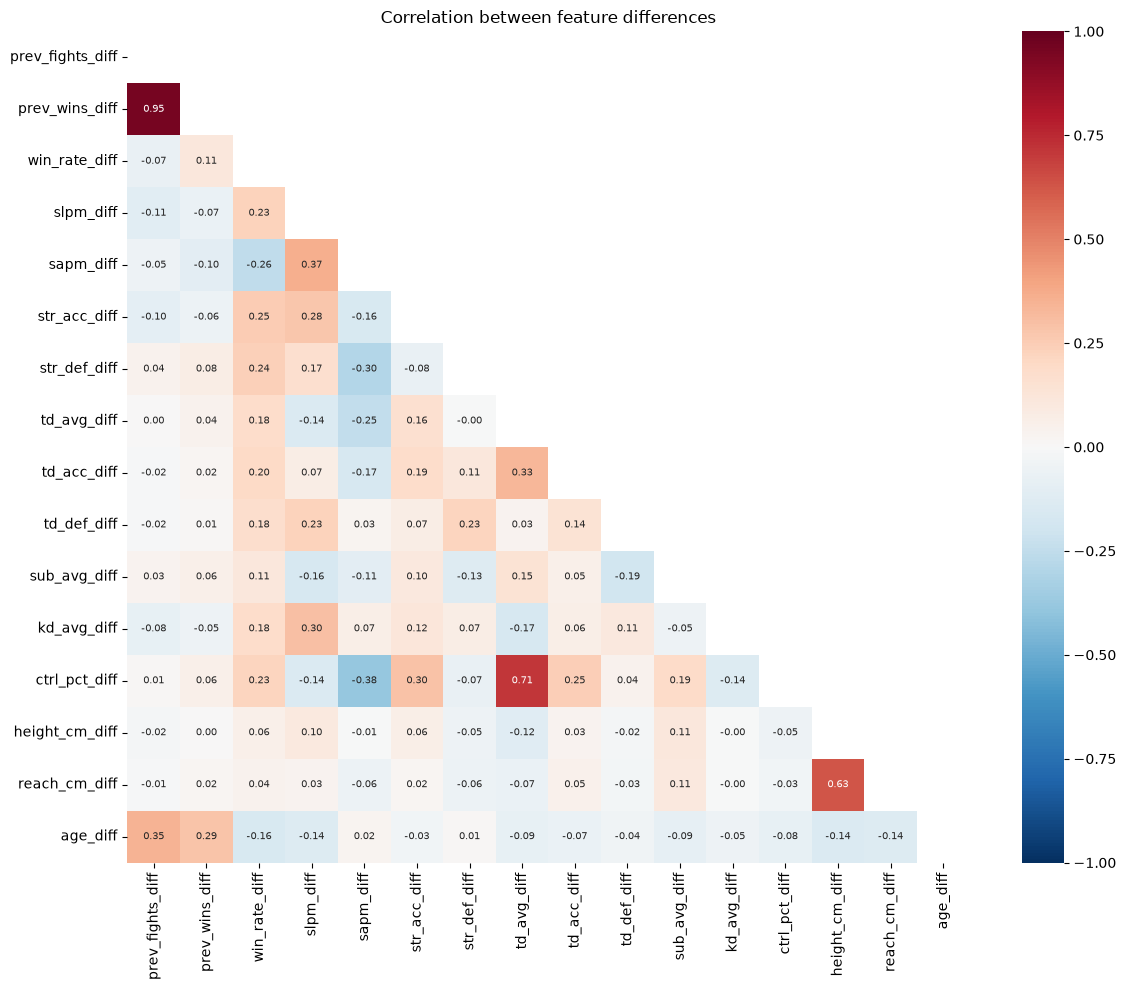

In [412]:
diff_cols = [c for c in train.columns if c.endswith("_diff")]
corr = train[diff_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between feature differences")
plt.tight_layout()

In [413]:
pairs = corr.where(~mask).stack()
pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False)

prev_wins_diff  prev_fights_diff    0.953654
ctrl_pct_diff   td_avg_diff         0.713871
reach_cm_diff   height_cm_diff      0.627108
dtype: float64

## Modeling

In [414]:
ID_COLS = ["DATE", "EVENT", "BOUT", "FIGHTER", "OPPONENT"]
FEATURES = [c for c in model_df.columns if c not in ID_COLS + ["win"]]

train_dicts = train[FEATURES].to_dict(orient="records")
val_dicts   = val[FEATURES].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)  
X_val   = dv.transform(val_dicts)         

y_train = train["win"].values
y_val   = val["win"].values

X_train.shape, X_val.shape

((13104, 40), (1986, 40))

In [415]:
train_dicts[0]
dv.get_feature_names_out()

array(['STANCE=Orthodox', 'STANCE=Southpaw', 'STANCE=Switch',
       'STANCE=Unknown', 'STANCE_b=Orthodox', 'STANCE_b=Southpaw',
       'STANCE_b=Switch', 'STANCE_b=Unknown', 'age_diff', 'ctrl_pct_diff',
       'height_cm_diff', 'is_title', 'is_women', 'kd_avg_diff',
       'prev_fights', 'prev_fights_b', 'prev_fights_diff',
       'prev_wins_diff', 'reach_cm_diff', 'same_stance', 'sapm_diff',
       'scheduled_rounds', 'slpm_diff', 'str_acc_diff', 'str_def_diff',
       'sub_avg_diff', 'td_acc_diff', 'td_avg_diff', 'td_def_diff',
       'weight_class=Bantamweight', 'weight_class=Catch Weight',
       'weight_class=Featherweight', 'weight_class=Flyweight',
       'weight_class=Heavyweight', 'weight_class=Light Heavyweight',
       'weight_class=Lightweight', 'weight_class=Middleweight',
       'weight_class=Strawweight', 'weight_class=Welterweight',
       'win_rate_diff'], dtype=object)

In [416]:
imputer = SimpleImputer(strategy="median")
X_train_i = imputer.fit_transform(X_train)
X_val_i   = imputer.transform(X_val) 

### LogisticRegression

**Logistic regression.** Features were imputed with the training median and standardised. The best validation result is **AUC 0.646 / log loss 0.657** (C = 0.1), clearly above the best single feature (age_diff, AUC 0.584) and the uninformed log loss of 0.693. Performance is flat for C ≥ 0.1: with ~13k training rows and ~40 features, regularization has little effect. C = 0.1 is chosen as the simplest model among the tied values.

In [417]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_i)
X_val_s   = scaler.transform(X_val_i)

for C in [0.001, 0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_s, y_train)
    y_pred = model.predict_proba(X_val_s)[:, 1]
    print(f"C={C:<6} AUC={roc_auc_score(y_val, y_pred):.4f}  logloss={log_loss(y_val, y_pred):.4f}")

C=0.001  AUC=0.6423  logloss=0.6623
C=0.01   AUC=0.6424  logloss=0.6593
C=0.1    AUC=0.6431  logloss=0.6586
C=1      AUC=0.6431  logloss=0.6586
C=10     AUC=0.6430  logloss=0.6586


### Random Forest

**Random forest.** Trained on median-imputed features (no scaling needed for trees). Parameters were tuned sequentially on the validation set:
- `max_depth`: 10 gave the best log loss (0.6608); deeper trees did not improve AUC and produced slightly worse probabilities.
- `min_samples_leaf`: 20 (AUC 0.6500 / log loss 0.6603); larger leaves smooth the predictions, which helps with noisy data.
- `n_estimators`: 200; going to 500 only added 0.0006 AUC while making the model 2.5× larger and slower.

Best random forest: **AUC 0.650 / log loss 0.660**, practically tied with logistic regression (0.646 / 0.657). This suggests the relationship between the features and the outcome is largely linear, and that the limit is the information in the features rather than the model.

In [418]:
depths = [5, 10, 15, 20, None]
estimators = [100, 200, 500]
leafs = [1, 5, 10, 20 ,50]

for depth in depths:
    rf = RandomForestClassifier(max_depth=depth, n_estimators=200, random_state=1, n_jobs=-1)

    rf.fit(X_train_i, y_train)
    y_pred = rf.predict_proba(X_val_i)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print(f"depth={depth}  AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}")

depth=5  AUC=0.6469  logloss=0.6677
depth=10  AUC=0.6448  logloss=0.6614
depth=15  AUC=0.6377  logloss=0.6641
depth=20  AUC=0.6388  logloss=0.6637
depth=None  AUC=0.6426  logloss=0.6637


In [419]:
for leaf in leafs:
    rf = RandomForestClassifier(max_depth=10, n_estimators=200, random_state=1, n_jobs=-1, min_samples_leaf=leaf)

    rf.fit(X_train_i, y_train)
    y_pred = rf.predict_proba(X_val_i)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print(f"leaf={leaf}  AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}")

leaf=1  AUC=0.6448  logloss=0.6614
leaf=5  AUC=0.6490  logloss=0.6598
leaf=10  AUC=0.6506  logloss=0.6594
leaf=20  AUC=0.6491  logloss=0.6606
leaf=50  AUC=0.6453  logloss=0.6624


In [420]:
for estimator in estimators:
    rf = RandomForestClassifier(max_depth=10, n_estimators=estimator, random_state=1, n_jobs=-1, min_samples_leaf=20)

    rf.fit(X_train_i, y_train)
    y_pred = rf.predict_proba(X_val_i)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print(f"estimator={estimator}  AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}")

estimator=100  AUC=0.6499  logloss=0.6601
estimator=200  AUC=0.6491  logloss=0.6606
estimator=500  AUC=0.6506  logloss=0.6600


### XGBoost

**XGBoost.** Trained on the raw features (missing values handled natively), with early stopping on the validation AUC (patience of 50 rounds). Parameters were tuned sequentially:
- `eta`: 0.05 (best log loss; 0.3 learned too aggressively).
- `max_depth`: 4. Shallower trees generalise better on such noisy data, while depth 6–8 overfitted within a few dozen rounds.
- `min_child_weight`: 10, which prevents leaves built on very few fights.

In [421]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [422]:
etas = [0.01, 0.05, 0.1, 0.3]
depths = [3, 4, 6, 8]
weights = [1, 5, 10, 20]

In [423]:
for eta in etas:

    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(
        xgb_params, dtrain, 
        num_boost_round=2000,
        evals=[(dtrain, "train"), (dval, "val")],
        early_stopping_rounds=50, 
        verbose_eval=False
    )

    y_pred = model.predict(dval, iteration_range=(0, model.best_iteration + 1))
    auc= roc_auc_score(y_val, y_pred)

    print(f"eta={eta:<5} AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}  best_iter={model.best_iteration}")

eta=0.01  AUC=0.6393  logloss=0.6621  best_iter=278
eta=0.05  AUC=0.6342  logloss=0.6636  best_iter=68
eta=0.1   AUC=0.6401  logloss=0.6612  best_iter=26
eta=0.3   AUC=0.6393  logloss=0.6615  best_iter=10


In [424]:
for depth in depths:

    xgb_params = {
        'eta': 0.05,
        'max_depth': depth,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(
        xgb_params, dtrain, 
        num_boost_round=2000,
        evals=[(dtrain, "train"), (dval, "val")],
        early_stopping_rounds=50, 
        verbose_eval=False
    )

    y_pred = model.predict(dval, iteration_range=(0, model.best_iteration + 1))
    auc= roc_auc_score(y_val, y_pred)

    print(f"depth={depth:<5} AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}  best_iter={model.best_iteration}")

depth=3     AUC=0.6440  logloss=0.6596  best_iter=101
depth=4     AUC=0.6439  logloss=0.6591  best_iter=84
depth=6     AUC=0.6342  logloss=0.6636  best_iter=68
depth=8     AUC=0.6389  logloss=0.6621  best_iter=54


In [425]:
for weight in weights:

    xgb_params = {
        'eta': 0.05,
        'max_depth': 4,
        'min_child_weight': weight,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(
        xgb_params, dtrain, 
        num_boost_round=2000,
        evals=[(dtrain, "train"), (dval, "val")],
        early_stopping_rounds=50, 
        verbose_eval=False
    )

    y_pred = model.predict(dval, iteration_range=(0, model.best_iteration + 1))
    auc= roc_auc_score(y_val, y_pred)

    print(f"weight={weight:<5} AUC={auc:.4f}  logloss={log_loss(y_val, y_pred):.4f}  best_iter={model.best_iteration}")

weight=1     AUC=0.6439  logloss=0.6591  best_iter=84
weight=5     AUC=0.6490  logloss=0.6572  best_iter=89
weight=10    AUC=0.6491  logloss=0.6572  best_iter=116
weight=20    AUC=0.6501  logloss=0.6562  best_iter=118


Best XGBoost: **AUC 0.650 / log loss 0.656** with 117 boosting rounds.

### Model selection

| Model | Val AUC | Val log loss |
|---|---|---|
| Baseline (best single feature, age_diff) | 0.584 | – |
| Logistic regression | 0.646 | 0.657 |
| Random forest | 0.650 | 0.660 |
| **XGBoost** | **0.650** | **0.656** |

All three models perform similarly, which suggests the limit lies in the information available before a fight rather than in the model. **XGBoost** is selected: it ties for the best AUC, has the best log loss (the most relevant metric, as the service returns probabilities) and handles missing values natively, so no imputation step is needed at serving time.

### Final evaluation on the test set

The selected XGBoost model (eta 0.05, max_depth 4, min_child_weight 10, 117 rounds) was retrained on train + validation (fights up to 2024) and evaluated **once** on the held-out test set (fights from 2025–2026):

In [426]:
train_final = model_df[model_df["DATE"] < "2025-01-01"]
test_final = model_df[model_df["DATE"] >= "2025-01-01"]

ID_COLS = ["DATE", "EVENT", "BOUT", "FIGHTER", "OPPONENT"]
FEATURES = [c for c in model_df.columns if c not in ID_COLS + ["win"]]

train_dicts = train_final[FEATURES].to_dict(orient="records")
test_dicts = test_final[FEATURES].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_test = dv.transform(test_dicts)        

y_train = train_final["win"].values
y_test = test_final['win'].values

In [427]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

In [428]:
xgb_params = {
    'eta': 0.05,
    'max_depth': 4,
    'min_child_weight': 10,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=117)

y_pred = model.predict(dtest)
print(f"Test AUC={roc_auc_score(y_test, y_pred):.4f}  logloss={log_loss(y_test, y_pred):.4f}")

Test AUC=0.6411  logloss=0.6636


| Set | AUC | Log loss |
|---|---|---|
| Validation (2023–2024) | 0.650 | 0.656 |
| **Test (2025–2026)** | **0.640** | **0.668** |

The small drop from validation to test is expected when predicting a later period, and shows that the model generalises to future fights without overfitting. Predicting MMA outcomes from historical statistics alone is hard, and the model is meant as a data-driven estimate rather than a certainty.

For deployment, the final model is retrained on **all available data** with the same parameters, so that it also learns from the most recent fights.

In [429]:
from features import build_matchup_features

row = build_matchup_features(snapshot, "Renato Moicano", "Ilia Topuria")
X = dv.transform([row])
model.predict(xgb.DMatrix(X, feature_names=list(dv.get_feature_names_out())))

array([0.33108538], dtype=float32)